Question 1

In [7]:
from IPython.core.pylabtools import figsize
from bs4 import BeautifulSoup
import requests, csv

In [8]:
project_url = "https://www.gumtree.co.za/s-houses-flats-for-sale/johannesburg/v1c9074l3100090p1"
headers = {"User-Agent": "Mozilla/5.0"}
html_page = requests.get(project_url).text # gets the retrieved page's from above declared url's html text
gum_soup = BeautifulSoup(html_page, "lxml")
gum_info = gum_soup.find_all("span", class_="related-item has-hover has-actions-bar")
gum_title, gum_desc, gum_location, gum_price, gum_list_link, gum_bedroom_count, gum_bathroom_count = [], [], [], [], [], [], []
count = 0

In [9]:
for gum_part in gum_info:
        gum_title.append(gum_part.find("a", class_="related-ad-title").span.text) # to get text inside title block which is stuck inside span tag then convert to text
        try:
            gum_desc.append(gum_part.find("div", class_="description-container").span.text)
        except AttributeError:
            gum_desc.append("N/a")
        try:
            gum_location.append(gum_part.find("span", class_="location").span.text)
        except AttributeError:
            gum_location.append("N/a")
        try:
            gum_price.append(gum_part.find("span", class_="ad-price").text.strip()) # strips returned text from span tag
        except AttributeError:
            gum_price.append("Contact f/price") # in case value was not set in tag
        gum_list_link.append("https://www.gumtree.co.za" + gum_part.find("a",attrs={"class":"related-ad-title"}).attrs["href"])
        entered_page = requests.get(gum_list_link[count]).text # to prevent giving an increasing list to requests module
        count += 1
        page_soup = BeautifulSoup(entered_page, "lxml")
        page_info = page_soup.find("div", class_="attributes")
        page_listings = page_info.find_all("div", class_="attribute")  # separating info for collection purposes
        try:
            for entry in page_listings: # using a for loop for checking
                if entry.find("span", class_="name").text == "Bedrooms (#):": # if entry matches specific span requirement
                    gum_bedroom_count.append(entry.find("span", class_="value").text) # then we add it to list
        except AttributeError:
            gum_bedroom_count.append("N/a")
        try:
            for entry in page_listings:
                if entry.find("span", class_="name").text == "Bathrooms (#):":
                    gum_bathroom_count.append(entry.find("span", class_="value").text)
        except AttributeError:
            gum_bathroom_count.append("N/a")

In [10]:
headings = ["PROPERTY_TITLE", "PROPERTY_DESC", "PROPERTY_LOCATION", "PROPERTY_PRICE", "PROPERTY_LISTING_LINK", "PROPERTY_BEDROOM_COUNT", "PROPERTY_BATHROOM COUNT"]
property_det_list = gum_title, gum_desc, gum_location, gum_price, gum_list_link, gum_bedroom_count, gum_bathroom_count

with open("gumtree_listings.csv", "w", newline="", encoding="utf-8") as csv_file:
    writer = csv.writer(csv_file)
    writer.writerow(headings)
    for i in range(len(gum_title)):
        writer.writerow([gum_title[i], gum_desc[i], gum_location[i], gum_price[i], gum_list_link[i], gum_bedroom_count[i], gum_bathroom_count[i]])
    print("DATA HAS BEEN SUCCESSFULLY WRITTEN AND SAVED.")

DATA HAS BEEN SUCCESSFULLY WRITTEN AND SAVED.


In [11]:
import pandas as pd

In [12]:
df = pd.read_csv("gumtree_listings.csv", encoding="utf-8", na_values=["N/a", "Contact f/price", "Other"])
df.dropna(inplace=True)


In [13]:
df["PROPERTY_PRICE"] = pd.to_numeric(df["PROPERTY_PRICE"].str.replace(r"^R\s", "", regex=True).str.replace(r",", "", regex=True)) #setting regex to true cause pandas changed it in an update


In [14]:
df["PROPERTY_BEDROOM_COUNT"] = df["PROPERTY_BEDROOM_COUNT"].astype(str).str.replace(r"\+", "", regex=True).astype(int)
df["PROPERTY_BATHROOM COUNT"] = df["PROPERTY_BATHROOM COUNT"].astype(str).str.replace(r"\+", "", regex=True).astype(int)

In [15]:
df.to_csv("sorted_data_file.csv", index=False)

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("sorted_data_file.csv")

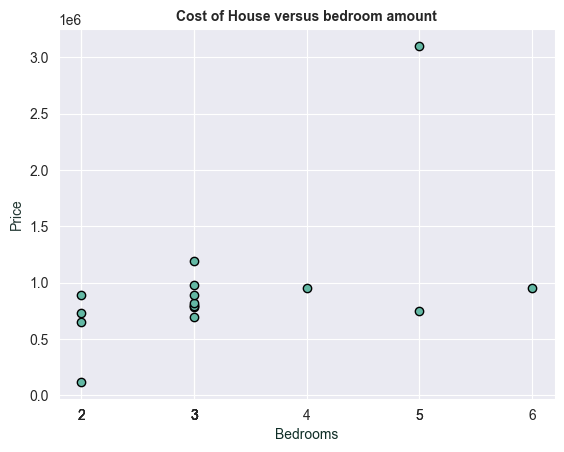

In [17]:
bedroom_amount = df["PROPERTY_BEDROOM_COUNT"]
price = df["PROPERTY_PRICE"]


plt.scatter(bedroom_amount, price, color="#63b8a4", edgecolors="black")
plt.title("Cost of House versus bedroom amount", font="Arial", fontweight="bold")
plt.xlabel("Bedrooms", color="#0f2e27", fontsize=10)
plt.ylabel("Price", color="#213631", fontsize=10)
plt.xticks(bedroom_amount)
plt.show()

Generally speaking, there is a trend where bedrooms influence the price of housing. This could be explained by construction costs of building extra bedrooms as well as perhaps the amount of floors and space used to construct them.

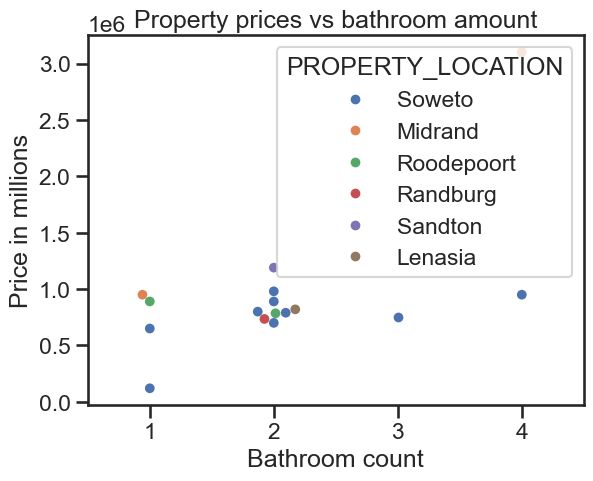

<Figure size 1200x800 with 0 Axes>

In [18]:
sns.set_theme(style="ticks", context="talk")
sns.swarmplot(x="PROPERTY_BATHROOM COUNT", y="PROPERTY_PRICE", data=df, hue="PROPERTY_LOCATION", s=7)
plt.xlabel("Bathroom count")
plt.ylabel("Price in millions")
plt.title("Property prices vs bathroom amount")
plt.figure(figsize=(12, 8))
plt.show()

Most properties sit within a count of two bathrooms, with the exception of a fourth and third amount. From this we can conclude that there is an ideal amount of bathrooms built into homes at an affordable selling point. That would suggest the market is most competitive around two bathrooms in a home.

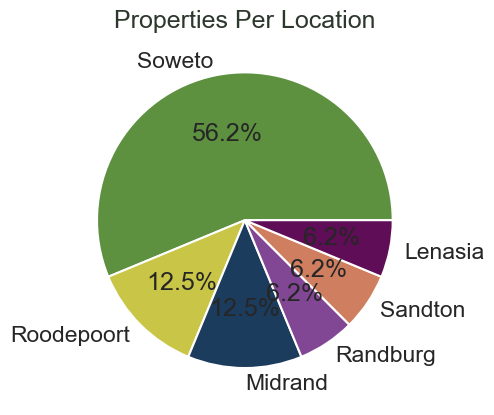

In [19]:
uniq_location_names = df["PROPERTY_LOCATION"].value_counts()

pie_colors = ["#5d913f",
              "#c9c547",
              "#1c3c5e",
              "#824794",
              "#cf7f5f",
              "#5e0d56"]
plt.pie(uniq_location_names,
        labels=uniq_location_names.index,
        autopct="%1.1f%%",
        colors=pie_colors,)
plt.title("Properties Per Location",
          font="Arial",
          color="#2d382d")
plt.show()


As seen above there are a variety of properties, however, some locations do dominate over others. This might be due to certain areas on the market holding higher value and therefore selling at higher prices leaving a shorter amount of properties available.

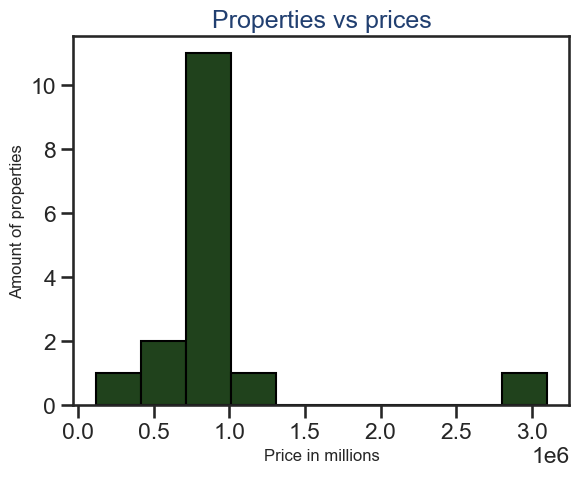

In [20]:
plt.hist(price,
         color="#20421c",
         edgecolor="black")
plt.title("Properties vs prices",
          color="#213f70")
plt.xlabel("Price in millions",
           fontsize=12)
plt.ylabel("Amount of properties",
           fontsize=12)
plt.show()

The data suggests that property values rarely exceed 1.5 million. This most likely is the mark self-regulating as potential home-owners choose not to purchases homes at that value.

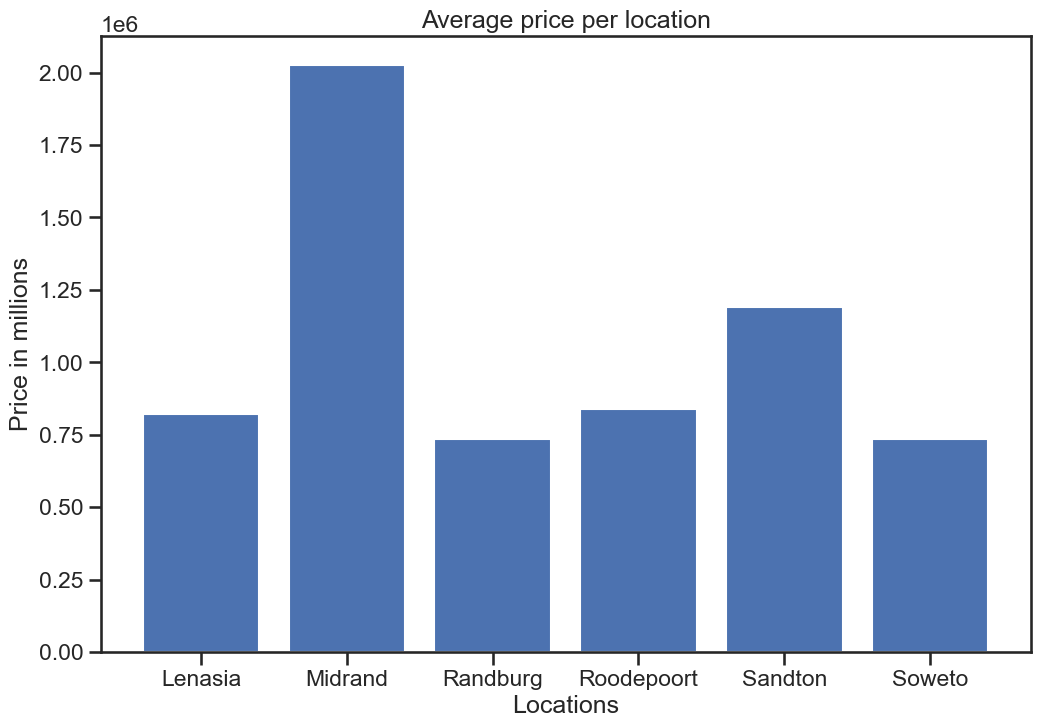

In [21]:
grouped_locations = df.groupby("PROPERTY_LOCATION") # gets grouped locations
grouped_locations_average = grouped_locations["PROPERTY_PRICE"].mean() # gets property price column average
plt.figure(figsize=(12,8))
plt.bar(grouped_locations_average.index, grouped_locations_average)
plt.title("Average price per location")
plt.xlabel("Locations")
plt.ylabel("Price in millions")
plt.show()

Midrand tends to lead with property value rated higher over the others , mainly due to its location and business value as an epicenter of Johannesburg.

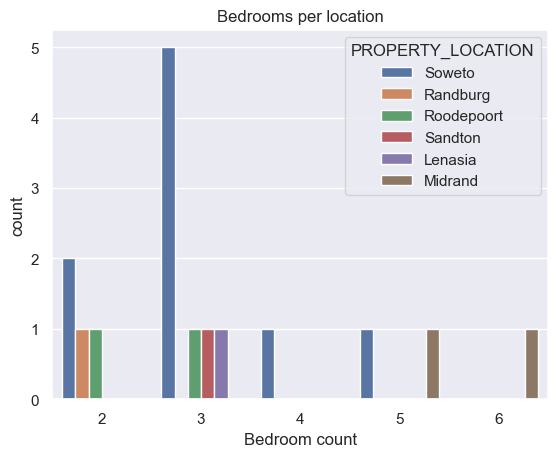

In [22]:
sns.set_theme()
sns.countplot(df, x="PROPERTY_BEDROOM_COUNT", hue="PROPERTY_LOCATION")
plt.title("Bedrooms per location")
plt.xlabel("Bedroom count")
plt.show()

Across the board, property location usually sit beneath two bedrooms suggesting a normal means across locations.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sorted_data_file.csv")
df["PROPERTY_LOCATION"] = df["PROPERTY_LOCATION"].astype("category").cat.codes
scaler = StandardScaler()
df[["PROPERTY_PRICE", "PROPERTY_LOCATION", "PROPERTY_BEDROOM_COUNT", "PROPERTY_BATHROOM COUNT"]] = scaler.fit_transform(df[["PROPERTY_PRICE", "PROPERTY_LOCATION", "PROPERTY_BEDROOM_COUNT", "PROPERTY_BATHROOM COUNT"]])

In [24]:
class KmeansClustering:

    def __init__(self, k=3):
        self.k = k
        self.centroids = None

    @staticmethod
    def euclidean_distance(data_point, centroids):
        return np.sqrt(np.sum((centroids - data_point)** 2, axis=1)) # mathematics formula for calculating distances between points

    def fit(self, X, max_iterations=200):
        self.centroids = np.random.uniform(np.amin(X, axis=0), np.amax(X, axis=0),
                                           size=(self.k, X.shape[1]))

        for _ in range(max_iterations):
            y = []

            for data_point in X:
                distances = KmeansClustering.euclidean_distance(data_point, self.centroids) # returns list of distances
                cluster_num = np.argmin(distances)
                y.append(cluster_num)

            y = np.array(y)
            cluster_indices = []

            for i in range(self.k): # for every cluster
                cluster_indices.append(np.argwhere(y == i))

            cluster_centers = []
            for i, indices in enumerate(cluster_indices):
                if len(indices) == 0:
                    cluster_centers.append(self.centroids[i])
                else:
                    cluster_centers.append(np.mean(X[indices], axis=0)[0])

            if np.max(self.centroids - np.array(cluster_centers)) < 0.0001:
                break
            else:
                self.centroids = np.array(cluster_centers)
        return y


In [25]:
def optimize_k_means(data, max_k):
    means = []
    inertias = []

    for k in range(1, max_k):
        kmeans = KMeans(n_clusters=k)
        kmeans.fit(data)

        means.append(k)
        inertias.append(kmeans.inertia_)

    #generating elbow plot
    fig = plt.subplots(figsize=(10,5))
    plt.plot(means, inertias, "o-")
    plt.xlabel("Number of Clusters")
    plt.ylabel("Inertia")
    plt.grid(True)
    plt.show()

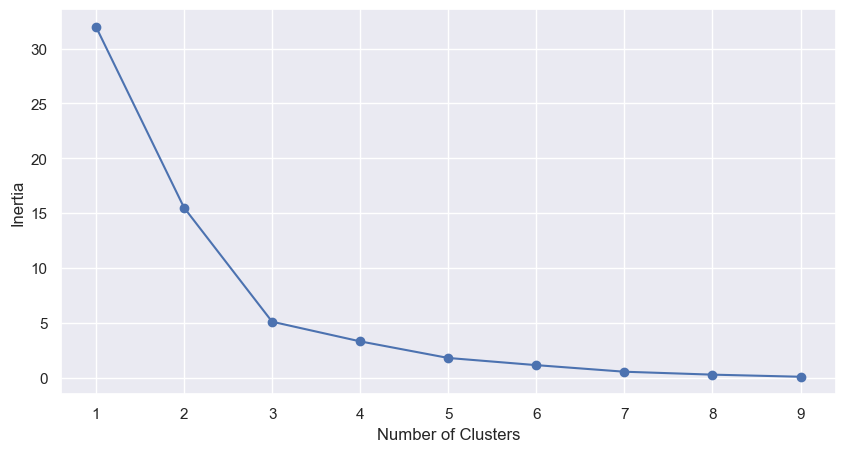

In [32]:
optimize_k_means(df[["PROPERTY_PRICE", "PROPERTY_LOCATION"]], 10)
optimal_k = 3
points = df[["PROPERTY_PRICE", "PROPERTY_LOCATION"]].values
kmeans = KmeansClustering(optimal_k)
labels = kmeans.fit(points)

3 is chosen

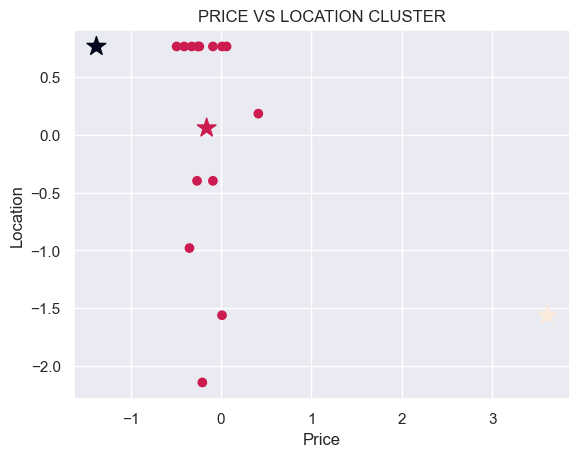

In [34]:
plt.scatter(points[:, 0], points[:, 1], c=labels)
plt.scatter(kmeans.centroids[:, 0], kmeans.centroids[:, 1],
            c=range(len(kmeans.centroids)),
            marker="*", s=200)
plt.title("PRICE VS LOCATION CLUSTER")
plt.xlabel("Price")
plt.ylabel("Location")
plt.show()

clusters focus on a single point with the other centroids becoming outliers.



note: I know now this code doesn't work because I tried to make one manually at the time

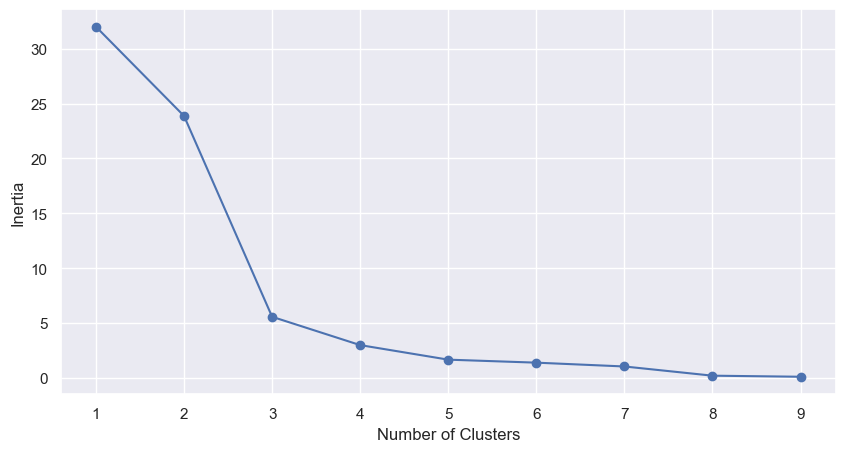

In [28]:
optimize_k_means(df[["PROPERTY_PRICE", "PROPERTY_BEDROOM_COUNT"]], 10)
optimal_k = 3
points = df[["PROPERTY_PRICE", "PROPERTY_BEDROOM_COUNT"]].values
kmeans = KmeansClustering(optimal_k)
labels = kmeans.fit(points)

3 is chosen

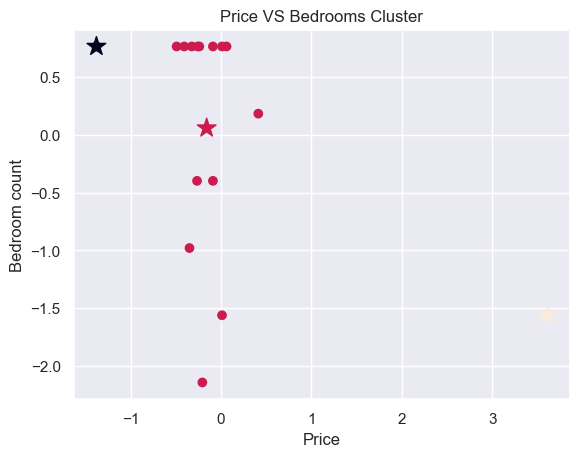

In [37]:
plt.scatter(points[:, 0], points[:, 1], c=labels)
plt.scatter(kmeans.centroids[:, 0], kmeans.centroids[:, 1],
            c=range(len(kmeans.centroids)),
            marker="*", s=200)
plt.title("Price VS Bedrooms Cluster")
plt.xlabel("Price")
plt.ylabel("Bedroom count")
plt.show()

We see a heavy similarity with clusters focusing on a single centroid.

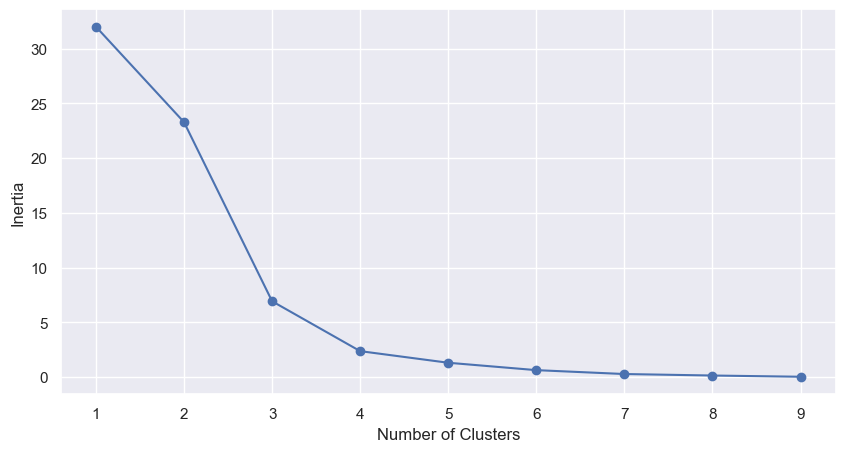

In [30]:
optimize_k_means(df[["PROPERTY_PRICE", "PROPERTY_BATHROOM COUNT"]], 10)
optimal_k = 3
points = df[["PROPERTY_PRICE", "PROPERTY_BATHROOM COUNT"]].values
kmeans = KmeansClustering(optimal_k)
labels = kmeans.fit(points)

3 is chosen.

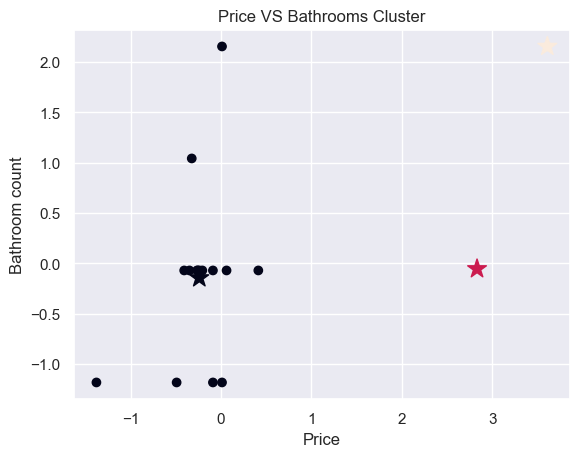

In [31]:
plt.scatter(points[:, 0], points[:, 1], c=labels)
plt.scatter(kmeans.centroids[:, 0], kmeans.centroids[:, 1],
            c=range(len(kmeans.centroids)),
            marker="*", s=200)
plt.title("Price VS Bathrooms Cluster")
plt.xlabel("Price")
plt.ylabel("Bathroom count")
plt.show()

clusters are discontinous in nature but still focus on a singular point in terms of distance.